In [25]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))

import numpy as np

from analysis import an_func as an_func
import analysis.io_func as io_func
import seaborn as sns
import matplotlib.pyplot as plt

from analysis import config_13c as config

## count reversible rxn and make fig4 (e for now)

In [26]:

# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [27]:
config.SAMPLINGDISTRIB_FOLDER

'/home/nathan/PhD/04.Computational/202601_13C//4_results//b_sampling/'

In [28]:
cond=condition='WT' 
model=config.model
net_flux_df=config.full_flux_df(condition)
all_samples=pd.read_csv(f'{config.SAMPLINGDISTRIB_FOLDER}/b3_flux_sampling/{cond}/{cond}fluxsamples.csv',index_col=0).T
obj_vals=config.obj_vals(condition)
# accepted_samples=obj_vals[obj_vals<= np.percentile(obj_vals,npercs)].index


## which reactions directions are fully determined in the sampling 

In [29]:
## could use sampled CRI instead of full sampled range but i am not
def sampling_percrange(samples:np.array,CI=95,bounds=False):
    
    sampling_ranges=pd.DataFrame(index=[r for r in net_flux_df.index])
    sampling_ranges['ub']=np.percentile(samples,CI,axis=1)
    sampling_ranges['lb']=np.percentile(samples,100-CI,axis=1)
    sampling_ranges['range']=sampling_ranges['ub']-sampling_ranges['lb']
    if bounds ==True : 
        return sampling_ranges[['lb','ub']]
    else :
        return sampling_ranges['range']
    
sampling_cri=sampling_percrange(net_flux_df.values,bounds=True,CI=95)
sampling_cri

,lb,ub
ASNS1,0.034098,0.036100
ASPK,0.147005,0.165841
ASPTA,-0.524163,-0.006053
ASPTAm,-0.451288,0.069548
ASAD,0.147005,0.165841
...,...,...
SUCCPItm-2-2,-0.378259,-0.013702
SUCFUMtm-2-2,-0.206279,0.105472
THRtm+0,0.062397,0.066058
biomass_ce,0.335285,0.354962


In [30]:
##count irreversible reactions and store
def get_irr_rxns(df):
    irreversible_count=0
    irr_rxns=[]
    for r_id in df.index:
        ### if all values in a column are >0 or <0, then the reaction is irreversible
        if all(df.loc[r_id].values>=0) or all(df.loc[r_id].values<=0):
            irreversible_count+=1
            irr_rxns.append(r_id)
    return irreversible_count,irr_rxns 

list_irr_rxn=get_irr_rxns(all_samples)[1]
list_irr_rxn_drawn=get_irr_rxns(net_flux_df)[1]

In [31]:
get_irr_rxns(all_samples)[0],get_irr_rxns(net_flux_df)[0]#,get_irr_rxns(sampling_cri)[0]

(238, 247)

## fig reversible reactions : 
count rev reactions from VA with met bounds, sampling df and drawn samples df

In [33]:
###make a df from 
nrxn_tot=282
blocked_rxn=12
comp_rev_df=pd.DataFrame([[89,92],[nrxn_tot-238,nrxn_tot-232],[nrxn_tot-247,nrxn_tot-235]],columns=['WT','TM6'],index=['VA','Sampling','13C_input'])
## make the numbers actually a percentage of the total number of reactions (282)
comp_rev_df=(comp_rev_df/nrxn_tot*100).astype(int)
comp_rev_df

,WT,TM6
VA,31,32
Sampling,15,17
13C_input,12,16


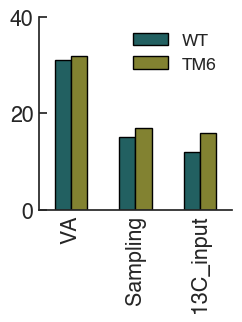

In [ ]:
## bar plot comp rev df
fig,ax=plt.subplots(figsize=(2.5,2.5))
io_func.scale_rcparams(fig)
comp_rev_df.plot(kind='bar',ax=ax,edgecolor='black',color=[palette[0]]+[palette[2]])
ax.legend(edgecolor='none')
ax.set_ylim(0,40)
plt.locator_params(axis='y', nbins=3)
# io_func.rescale_axlim(ax,how='y',nbins=3)
# ax.set_ylabel('% of reversible \n reactions')
# # ##save fig
# plt.savefig(f'{config.PLOTS_FOLDER}/fig4e_compare_percent_reversible.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}/fig4e_compare_percent_reversible.svg',dpi=300,bbox_inches='tight')